In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import scipy.stats as stats

In [104]:
df=pd.read_csv("statistics_practice.csv")

In [105]:
df

,Age,Height_cm,Performance_Score,Salary,Experience_Years,Department,Monthly_Hours,Training_Hours
0,37.44,169.41,71.38,82506.53,16.20,Marketing,175.18,7.90
1,26.68,162.71,69.67,59657.51,7.37,IT,166.17,12.20
2,41.00,165.86,78.47,88270.36,19.82,IT,189.91,2.71
3,42.52,176.34,77.01,142481.82,27.24,Finance,139.57,5.74
4,19.39,170.03,63.76,53135.05,1.68,IT,148.90,1.28
...,...,...,...,...,...,...,...,...
995,37.82,173.92,68.87,70839.84,19.05,Marketing,146.44,14.54
996,41.13,173.04,65.32,94798.01,18.10,IT,167.86,3.42
997,35.97,169.08,93.65,131657.69,16.31,Marketing,168.79,1.60
998,36.05,164.69,81.56,87857.43,14.20,IT,155.17,4.43


In [106]:
df.columns

Index(['Age', 'Height_cm', 'Performance_Score', 'Salary', 'Experience_Years',
       'Department', 'Monthly_Hours', 'Training_Hours'],
      dtype='str')

In [107]:
df.isnull().sum()

Age                  0
Height_cm            0
Performance_Score    0
Salary               0
Experience_Years     0
Department           0
Monthly_Hours        0
Training_Hours       0
dtype: int64

In [108]:
df.duplicated().sum()

np.int64(0)

In [109]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                1000 non-null   float64
 1   Height_cm          1000 non-null   float64
 2   Performance_Score  1000 non-null   float64
 3   Salary             1000 non-null   float64
 4   Experience_Years   1000 non-null   float64
 5   Department         1000 non-null   str    
 6   Monthly_Hours      1000 non-null   float64
 7   Training_Hours     1000 non-null   float64
dtypes: float64(7), str(1)
memory usage: 62.6 KB


In [110]:
# it only works on numerical columns 
# it will rerurn all the descriptive all each columns
df.describe()

,Age,Height_cm,Performance_Score,Salary,Experience_Years,Monthly_Hours,Training_Hours
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,34.824260,169.186340,75.269560,84380.521810,12.954040,160.156430,8.095010
std,7.772065,10.145532,8.133759,30630.454597,7.934386,14.916889,5.592602
min,18.000000,139.520000,50.490000,33482.900000,0.000000,110.530000,0.180000
25%,29.427500,162.695000,69.717500,62196.350000,7.062500,149.980000,4.057500
50%,35.050000,169.565000,75.290000,79160.675000,12.940000,160.305000,6.585000
75%,39.722500,176.030000,80.810000,99984.650000,18.002500,170.072500,11.050000
max,60.000000,199.140000,99.480000,242576.440000,40.000000,209.050000,34.100000


In [111]:
df.columns

Index(['Age', 'Height_cm', 'Performance_Score', 'Salary', 'Experience_Years',
       'Department', 'Monthly_Hours', 'Training_Hours'],
      dtype='str')

# Univariate analysis

C:\Users\Divyanshu\AppData\Local\Temp\ipykernel_9332\2913500950.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Salary"])


<Axes: xlabel='Salary', ylabel='Density'>

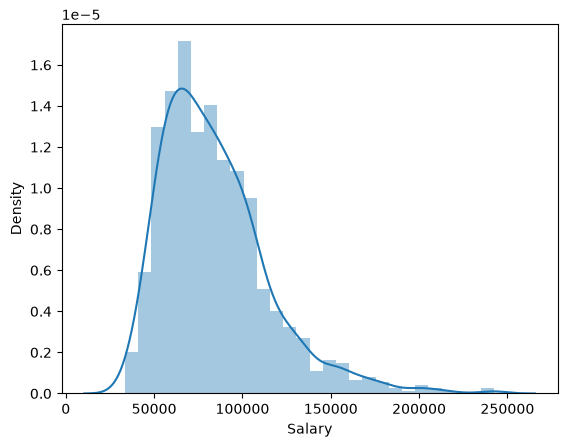

In [112]:
# cheak the distribultion of the target columns
sns.distplot(df["Salary"])

In [113]:
stats.skew(df["Salary"])

np.float64(1.3191838238003095)

In [114]:
stats.kurtosis(df["Salary"])

np.float64(2.6787077410462423)

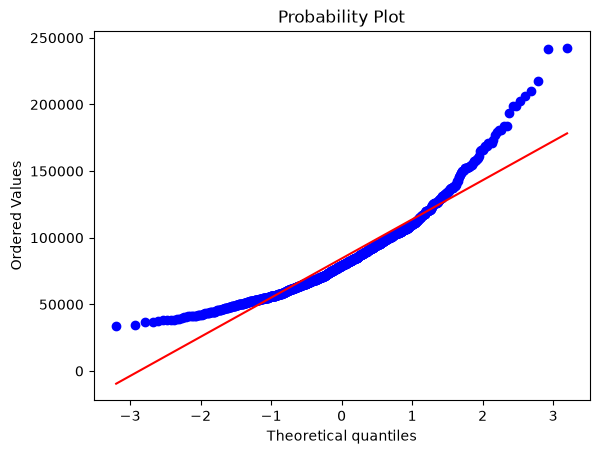

In [115]:
stats.probplot(df["Salary"],dist="norm",plot=plt)
plt.show()

In [116]:
def central_limit_therom(data,no_of_samples,sample_size):
    result=[]
    for i in range(no_of_samples):
        sample=np.random.choice(data,size=sample_size,replace=True)
        result.append(np.mean(sample))
    data=np.array(result)
    return data

In [117]:
data=df["Salary"]
no_of_samples=1000
sample_size=30
values=central_limit_therom(data,no_of_samples,sample_size)

In [118]:
import math
def gaussian_CDF(data):
    mean = np.mean(data)
    sd = np.std(data)
    result = []

    for i in data:
        ans = (i - mean) / (np.sqrt(2) * sd)
        res = 0.5 * (1 + math.erf(ans))
        result.append(res)

    return np.array(result)


In [119]:
data=np.sort(values)
cdf_values=gaussian_CDF(data)

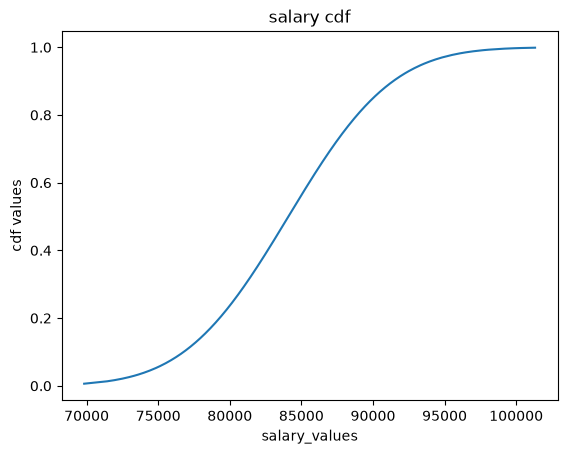

In [120]:
plt.xlabel("salary_values")
plt.ylabel("cdf values")
plt.title("salary cdf")
plt.plot(data,cdf_values)
plt.show()

In [121]:
def empirical_properties_GD(data,k):
    mean=np.mean(data)
    sd=np.std(data)
    LL=(mean-k*sd)
    UL=(mean+k*sd)
    return (LL,UL)

In [122]:
rang = empirical_properties_GD(df["Salary"],2)

In [123]:
rang

(np.float64(23150.250732907072), np.float64(145610.79288709295))

In [124]:
def chebyshevs_inequality(data,k):
    mean=np.mean(data)
    sd=np.std(data)
    LL=(mean-k*sd)
    UL=(mean+k*sd)
    per=(1-(1/k**2))*100
    return (LL,UL),per

In [125]:
rang,per=chebyshevs_inequality(df["Salary"],2)

In [126]:
rang

(np.float64(23150.250732907072), np.float64(145610.79288709295))

In [127]:
per


75.0

In [128]:
np.max((df["Salary"]))

np.float64(242576.44)

In [129]:
def convert_salary_cat(x):
    if x>=33000 and x<=80000:
        return "level 1"
    elif x>80000 and x<=150000:
        return "level 2"
    else:
        return "level 3"

In [130]:
df["sal_cat"]=df["Salary"].apply(convert_salary_cat)

<Axes: xlabel='sal_cat'>

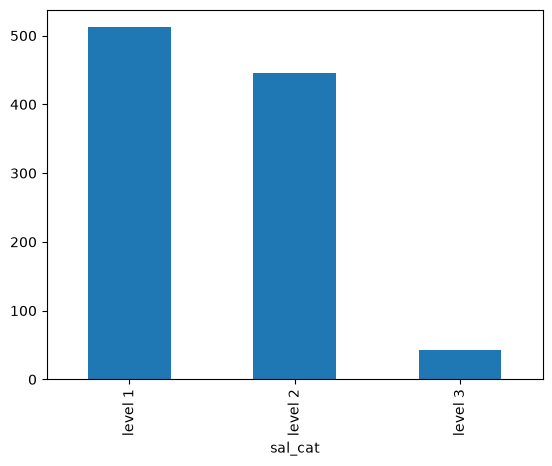

In [131]:
df["sal_cat"].value_counts().plot(kind="bar")

In [132]:
df.columns

Index(['Age', 'Height_cm', 'Performance_Score', 'Salary', 'Experience_Years',
       'Department', 'Monthly_Hours', 'Training_Hours', 'sal_cat'],
      dtype='str')

In [133]:
df.drop(columns=["Height_cm"],inplace=True)

C:\Users\Divyanshu\AppData\Local\Temp\ipykernel_9332\1875822968.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Performance_Score"])


<Axes: xlabel='Performance_Score', ylabel='Density'>

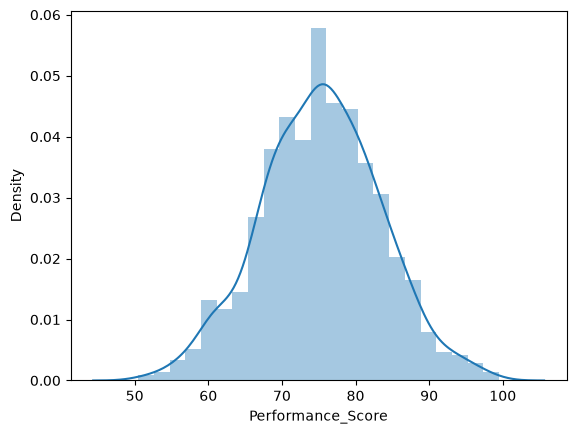

In [134]:
sns.distplot(df["Performance_Score"])

In [135]:
df.columns

Index(['Age', 'Performance_Score', 'Salary', 'Experience_Years', 'Department',
       'Monthly_Hours', 'Training_Hours', 'sal_cat'],
      dtype='str')

In [136]:
data=df["Performance_Score"]
no_of_samples=1000
sample_size=30
values_perfomance=central_limit_therom(data,no_of_samples,sample_size)

In [137]:
data=np.sort(values_perfomance)
cdf_values_perfomance=gaussian_CDF(data)

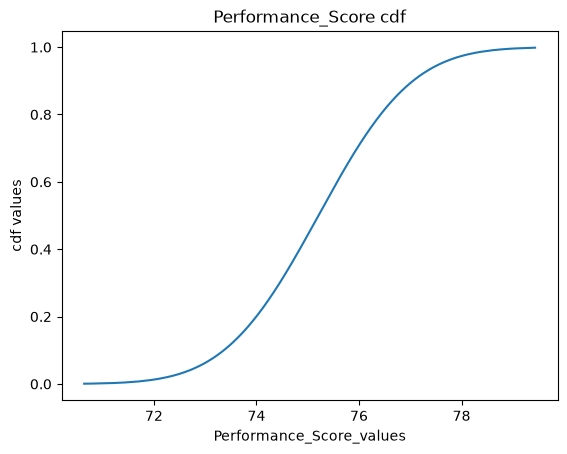

In [138]:
plt.xlabel("Performance_Score_values")
plt.ylabel("cdf values")
plt.title("Performance_Score cdf")
plt.plot(data,cdf_values_perfomance)
plt.show()

In [139]:
stats.skew(df["Performance_Score"])

np.float64(-0.01675332601198978)

In [140]:
stats.kurtosis(df["Performance_Score"])

np.float64(-0.034301572884246845)

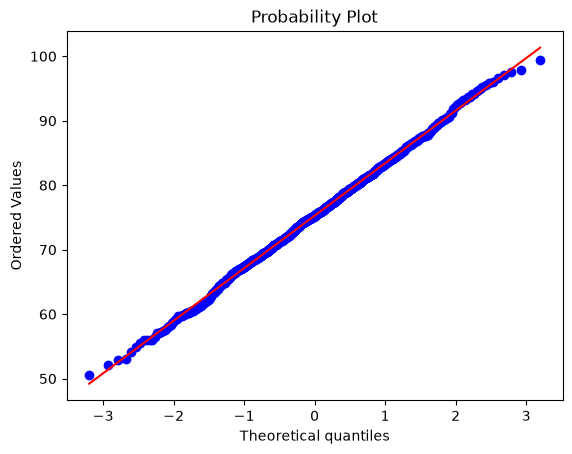

In [141]:
stats.probplot(df["Performance_Score"],dist="norm",plot=plt)
plt.show()

In [142]:
df.columns

Index(['Age', 'Performance_Score', 'Salary', 'Experience_Years', 'Department',
       'Monthly_Hours', 'Training_Hours', 'sal_cat'],
      dtype='str')

In [143]:
min(df["Performance_Score"])

50.49

In [144]:
max(df["Performance_Score"])

99.48

In [145]:
def performance_cat(x):
    if x>50 and x<65:
        return "low"
    elif x>65 and x<=80:
        return "average"
    else:
        return "high"

In [146]:
df["per_cat"]=df["Performance_Score"].apply(performance_cat)

In [147]:
df["per_cat"].value_counts()

per_cat
average    617
high       280
low        103
Name: count, dtype: int64

<Axes: xlabel='per_cat'>

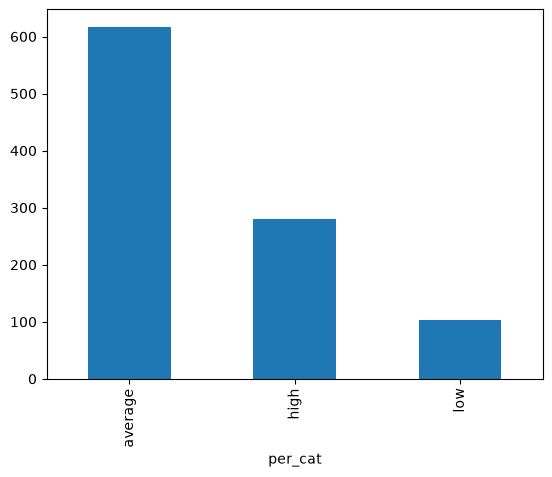

In [148]:
df["per_cat"].value_counts().plot(kind="bar")

In [149]:
high_score=df[df["per_cat"]=="high"]


In [150]:
np.mean(high_score["Salary"])

np.float64(89230.24692857143)

In [151]:
np.mean(high_score["Performance_Score"])

np.float64(84.99957142857141)

In [152]:
df.columns

Index(['Age', 'Performance_Score', 'Salary', 'Experience_Years', 'Department',
       'Monthly_Hours', 'Training_Hours', 'sal_cat', 'per_cat'],
      dtype='str')

In [153]:
sns.FaceGrid(df,hue="sal_cat",height=4).map(sns.distplot,"Salary").add_length()
plt.show()

AttributeError: module 'seaborn' has no attribute 'FaceGrid'

C:\Users\Divyanshu\miniconda3\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  func(*plot_args, **plot_kwargs)
C:\Users\Divyanshu\miniconda3\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  func(*plot_args, **plot_kwargs)
C:\Users\Divyanshu\m

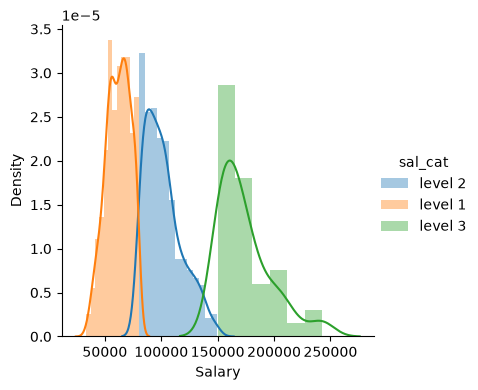

In [156]:
sns.FacetGrid(df, hue="sal_cat", height=4).map(sns.distplot, "Salary", kde=True).add_legend()

plt.show()

In [157]:
df.columns

Index(['Age', 'Performance_Score', 'Salary', 'Experience_Years', 'Department',
       'Monthly_Hours', 'Training_Hours', 'sal_cat', 'per_cat'],
      dtype='str')

C:\Users\Divyanshu\AppData\Local\Temp\ipykernel_9332\294390059.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Experience_Years"])


<Axes: xlabel='Experience_Years', ylabel='Density'>

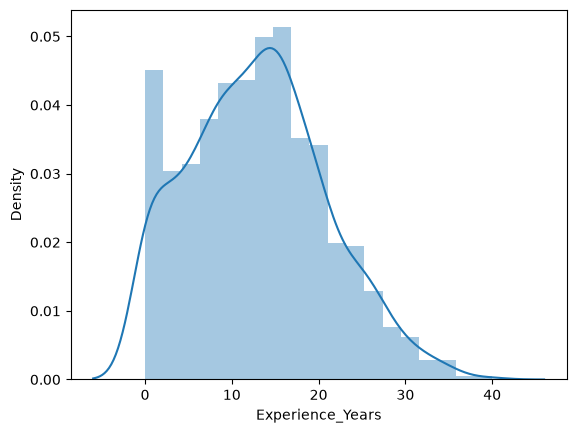

In [160]:
sns.distplot(df["Experience_Years"])

In [161]:
stats.skew(df["Experience_Years"])

np.float64(0.32469597940061257)

In [162]:
stats.kurtosis(df["Experience_Years"])

np.float64(-0.3126158068873117)

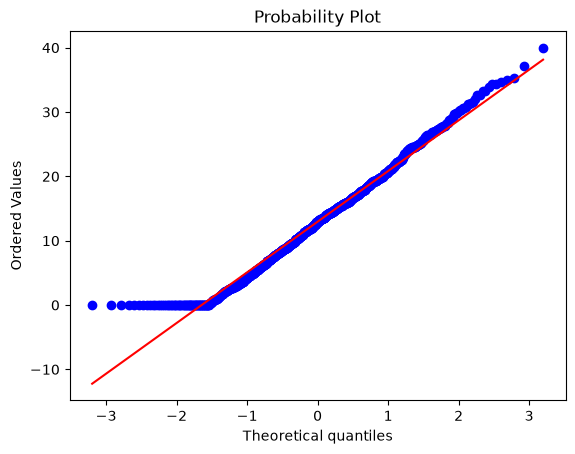

In [163]:
stats.probplot(df["Experience_Years"],dist="norm",plot=plt)
plt.show()

In [164]:
data=df["Experience_Years"]
no_of_samples=1000
sample_size=30
values_Experience=central_limit_therom(data,no_of_samples,sample_size)

In [165]:
data=np.sort(values_Experience)
cdf_values_Experience=gaussian_CDF(data)

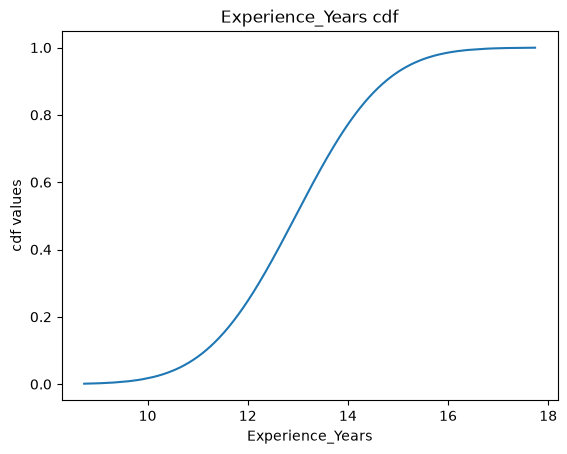

In [167]:
plt.xlabel("Experience_Years")
plt.ylabel("cdf values")
plt.title("Experience_Years cdf")
plt.plot(data,cdf_values_Experience)
plt.show()

In [168]:
min(df["Experience_Years"])

0.0

In [169]:
max(df["Experience_Years"])

40.0

In [171]:
df.columns

Index(['Age', 'Performance_Score', 'Salary', 'Experience_Years', 'Department',
       'Monthly_Hours', 'Training_Hours', 'sal_cat', 'per_cat'],
      dtype='str')